# CNN Optimization and interpretation Demo – MNIST
This notebook demonstrates how to apply several optimization techniques for CNNs and interpretability tools:
- Batch Normalization
- Dropout
- Learning rate scheduler
- Early stopping
- Data augmentation
- Confusion matrix
- Precision, Recall, F1-score


# Import required libraries

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

## Load and preprocess MNIST data

In [ ]:

from sklearn.model_selection import train_test_split

(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

# Split the full training set into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.2, random_state=42)

x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_val = x_val.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

y_train = to_categorical(y_train, 10)
y_val = to_categorical(y_val, 10)
y_test = to_categorical(y_test, 10)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Data Augmentation

In [ ]:
# Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1
)
datagen.fit(x_train)

## Build CNN with Dropout & BatchNorm

In [ ]:

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

## Callbacks for optimization

In [ ]:
# Callbacks for optimization
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
lr_schedule = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)

## Train the model with data augmentation

In [ ]:
# Train the model with data augmentation
history = model.fit(
    datagen.flow(x_train, y_train, batch_size=64),
    epochs=20,
    validation_data=(x_val, y_val), # Use the validation data split earlier
    steps_per_epoch=len(x_train) // 64,
    callbacks=[early_stop, lr_schedule],
    verbose=2
)

Epoch 1/20


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


750/750 - 83s - 111ms/step - accuracy: 0.7846 - loss: 0.6757 - val_accuracy: 0.9698 - val_loss: 0.0920 - learning_rate: 1.0000e-03
Epoch 2/20
750/750 - 82s - 109ms/step - accuracy: 0.9183 - loss: 0.2712 - val_accuracy: 0.9778 - val_loss: 0.0721 - learning_rate: 1.0000e-03
Epoch 3/20
750/750 - 75s - 100ms/step - accuracy: 0.9364 - loss: 0.2115 - val_accuracy: 0.9809 - val_loss: 0.0599 - learning_rate: 1.0000e-03
Epoch 4/20
750/750 - 84s - 112ms/step - accuracy: 0.9478 - loss: 0.1783 - val_accuracy: 0.9859 - val_loss: 0.0477 - learning_rate: 1.0000e-03
Epoch 5/20
750/750 - 74s - 99ms/step - accuracy: 0.9519 - loss: 0.1617 - val_accuracy: 0.9877 - val_loss: 0.0391 - learning_rate: 1.0000e-03
Epoch 6/20
750/750 - 75s - 100ms/step - accuracy: 0.9548 - loss: 0.1527 - val_accuracy: 0.9890 - val_loss: 0.0357 - learning_rate: 1.0000e-03
Epoch 7/20
750/750 - 76s - 102ms/step - accuracy: 0.9582 - loss: 0.1433 - val_accuracy: 0.9892 - val_loss: 0.0386 - learning_rate: 1.0000e-03
Epoch 8/20
750/750

## Evaluate the model

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.9938


# Plot training history

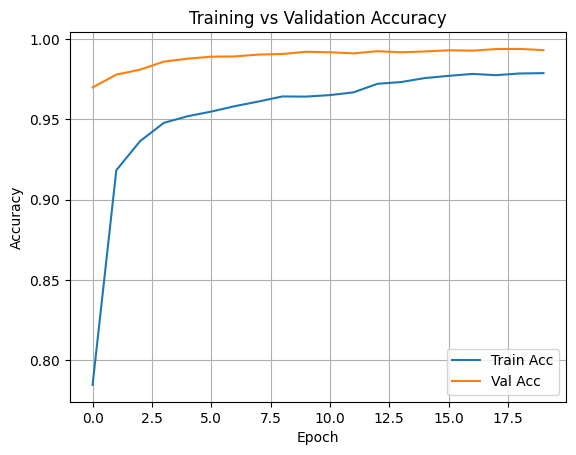

In [ ]:
# Plot training history
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## Confusion Matrix

375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step


<Figure size 1000x800 with 0 Axes>

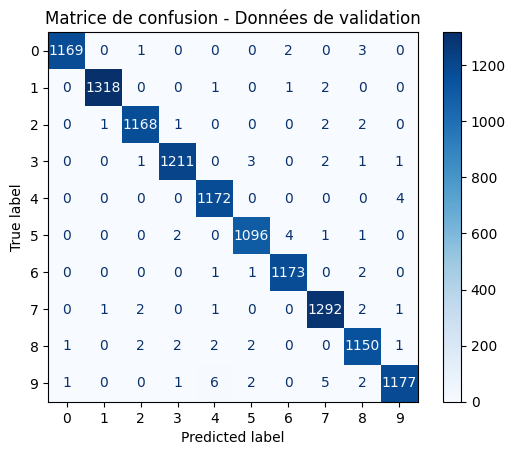

In [ ]:

# 1. Predictions on validation data
y_pred_probs = model.predict(x_val)
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Class predictions
y_true = np.argmax(y_val, axis=1)                # Real labels in classes

# 2. Calculation of the confusion matrix
cm = confusion_matrix(y_true, y_pred_classes)

# 3. Confusion matrix display
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Matrice de confusion - Données de validation")
plt.show()



## Precision, Recall, F1-score

In [ ]:
# 4. Rapport de classification
print("=== Rapport classification (Precision, Recall, F1-score) ===\n")
print(classification_report(y_true, y_pred_classes))

=== Rapport classification (Precision, Recall, F1-score) ===

              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1175
           1       1.00      1.00      1.00      1322
           2       0.99      0.99      0.99      1174
           3       1.00      0.99      0.99      1219
           4       0.99      1.00      0.99      1176
           5       0.99      0.99      0.99      1104
           6       0.99      1.00      1.00      1177
           7       0.99      0.99      0.99      1299
           8       0.99      0.99      0.99      1160
           9       0.99      0.99      0.99      1194

    accuracy                           0.99     12000
   macro avg       0.99      0.99      0.99     12000
weighted avg       0.99      0.99      0.99     12000

